In [2]:
import pandas as pd

df = pd.read_csv("../data/raw/bot_detection_data.csv")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
df.head()


Shape: (50000, 11)
Columns: ['User ID', 'Username', 'Tweet', 'Retweet Count', 'Mention Count', 'Follower Count', 'Verified', 'Bot Label', 'Location', 'Created At', 'Hashtags']


,User ID,Username,Tweet,Retweet Count,Mention Count,Follower Count,Verified,Bot Label,Location,Created At,Hashtags
0,132131,flong,Station activity person against natural majori...,85,1,2353,False,1,Adkinston,2020-05-11 15:29:50,NaN
1,289683,hinesstephanie,Authority research natural life material staff...,55,5,9617,True,0,Sanderston,2022-11-26 05:18:10,both live
2,779715,roberttran,Manage whose quickly especially foot none to g...,6,2,4363,True,0,Harrisonfurt,2022-08-08 03:16:54,phone ahead
3,696168,pmason,Just cover eight opportunity strong policy which.,54,5,2242,True,1,Martinezberg,2021-08-14 22:27:05,ever quickly new I
4,704441,noah87,Animal sign six data good or.,26,3,8438,False,1,Camachoville,2020-04-13 21:24:21,foreign mention


In [9]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Standardize column names (lowercase with underscores)
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")

# 2. Check missing values before cleaning
print("--- MISSING VALUES BEFORE CLEANING ---")
print(df.isna().sum())

# 3. Clean duplicates, dates, and missing text fields
df = df.drop_duplicates()
df["created_at"] = pd.to_datetime(df["created_at"], errors="coerce")
df["location"] = df["location"].fillna("Unknown")
df["hashtags"] = df["hashtags"].fillna("")
df["verified"] = df["verified"].astype(int)

# 4. Feature Engineering (Creating Business Analyst Behavioral Signals)
df["tweet_length"] = df["tweet"].astype(str).str.len()
df["hashtag_count"] = df["hashtags"].astype(str).apply(lambda x: len([h for h in x.split() if h]))
df["has_location"] = (df["location"] != "Unknown").astype(int)
df["account_age_days"] = (pd.Timestamp.today() - df["created_at"]).dt.days
df["engagement"] = df["retweet_count"] + df["mention_count"]
df["username_len"] = df["username"].astype(str).str.len()
df["username_digits"] = df["username"].astype(str).str.count(r"\d")

# 5. Drop any rows where engineered features or target label became null
features = [
    "retweet_count", "mention_count", "follower_count", "verified",
    "tweet_length", "hashtag_count", "has_location",
    "account_age_days", "engagement", "username_len", "username_digits"
]
df = df.dropna(subset=features + ["bot_label"])

# 6. Save cleaned dataset to data/processed/
df.to_csv("../data/processed/cleaned_data.csv", index=False)
print("\nCleaned dataset saved! Final shape:", df.shape)


--- MISSING VALUES BEFORE CLEANING ---
user_id             0
username            0
tweet               0
retweet_count       0
mention_count       0
follower_count      0
verified            0
bot_label           0
location            0
created_at          0
hashtags            0
tweet_length        0
hashtag_count       0
has_location        0
account_age_days    0
engagement          0
username_len        0
username_digits     0
nearest_dist        0
nearest_user        0
fake_probability    0
risk_tier           0
dtype: int64

Cleaned dataset saved! Final shape: (50000, 22)


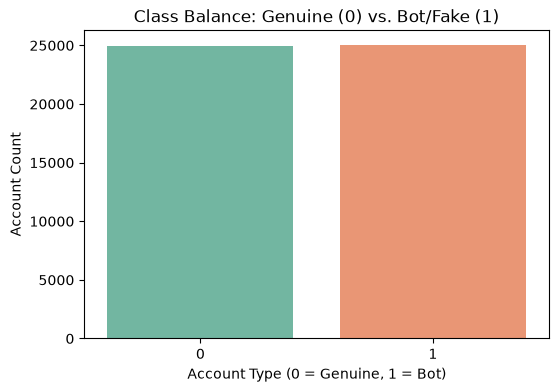

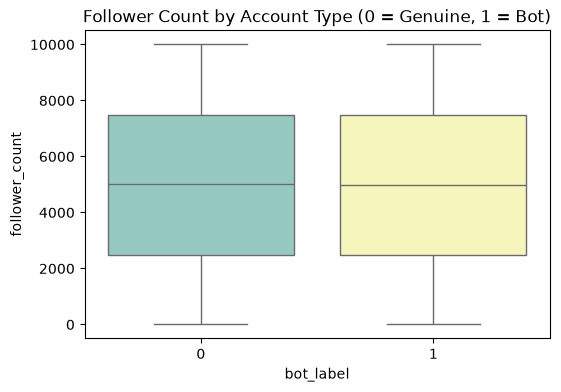

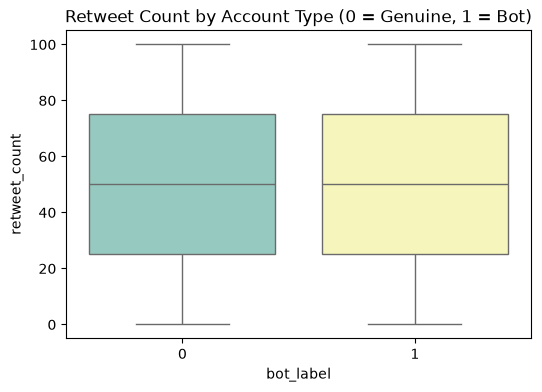

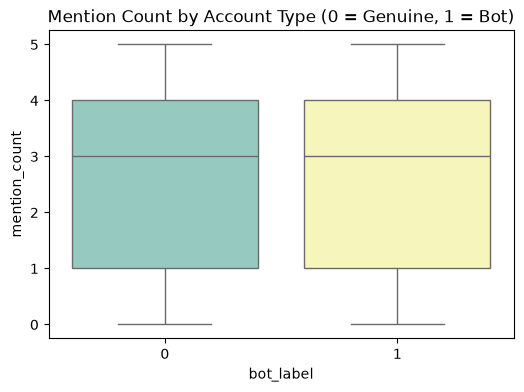

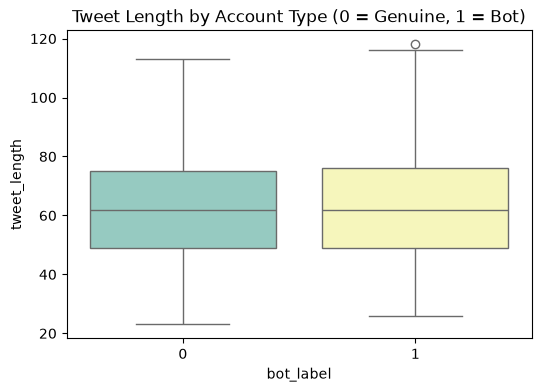

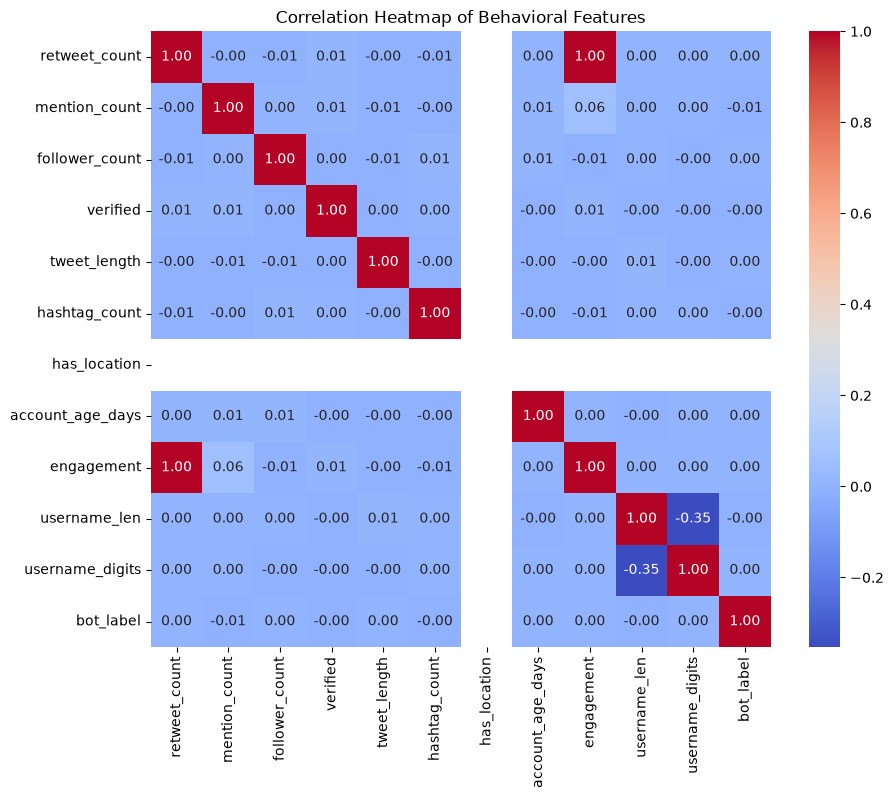

In [10]:
# Chart 1: Bot vs Human Account Balance
plt.figure(figsize=(6, 4))
sns.countplot(x="bot_label", data=df, hue="bot_label", palette="Set2", legend=False)
plt.title("Class Balance: Genuine (0) vs. Bot/Fake (1)")
plt.xlabel("Account Type (0 = Genuine, 1 = Bot)")
plt.ylabel("Account Count")
plt.savefig("../images/01_class_balance.png", dpi=150, bbox_inches="tight")
plt.show()

# Charts 2a–2d: Behavioral Distributions across Key Metrics
for idx, col in enumerate(["follower_count", "retweet_count", "mention_count", "tweet_length"], start=1):
    plt.figure(figsize=(6, 4))
    sns.boxplot(x="bot_label", y=col, data=df, hue="bot_label", palette="Set3", legend=False)
    plt.title(f"{col.replace('_', ' ').title()} by Account Type (0 = Genuine, 1 = Bot)")
    plt.savefig(f"../images/02{chr(96+idx)}_{col}_box.png", dpi=150, bbox_inches="tight")
    plt.show()

# Chart 3: Feature Correlation Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df[features + ["bot_label"]].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap of Behavioral Features")
plt.savefig("../images/03_correlation.png", dpi=150, bbox_inches="tight")
plt.show()


In [11]:
kpi = {
    "Total accounts": len(df),
    "Fake/bot rate (%)": round(df["bot_label"].mean() * 100, 2),
    "Verified among bots (%)": round(df[df.bot_label == 1]["verified"].mean() * 100, 2),
    "Verified among humans (%)": round(df[df.bot_label == 0]["verified"].mean() * 100, 2),
    "Avg followers - bots": round(df[df.bot_label == 1]["follower_count"].mean(), 1),
    "Avg followers - humans": round(df[df.bot_label == 0]["follower_count"].mean(), 1),
    "Avg engagement - bots": round(df[df.bot_label == 1]["engagement"].mean(), 1),
    "Avg engagement - humans": round(df[df.bot_label == 0]["engagement"].mean(), 1),
}

kpi_series = pd.Series(kpi)
kpi_series.to_csv("../outputs/kpis.csv", header=["Value"])
print("--- BUSINESS KPI SUMMARY ---")
print(kpi_series)


--- BUSINESS KPI SUMMARY ---
Total accounts               50000.00
Fake/bot rate (%)               50.04
Verified among bots (%)         49.88
Verified among humans (%)       50.14
Avg followers - bots          4991.90
Avg followers - humans        4985.30
Avg engagement - bots           52.50
Avg engagement - humans         52.50
dtype: float64


--- LOGISTIC REGRESSION REPORT ---
              precision    recall  f1-score   support

           0       0.49      0.48      0.49      4996
           1       0.49      0.51      0.50      5004

    accuracy                           0.49     10000
   macro avg       0.49      0.49      0.49     10000
weighted avg       0.49      0.49      0.49     10000

--- RANDOM FOREST REPORT ---
              precision    recall  f1-score   support

           0       0.50      0.51      0.50      4996
           1       0.50      0.48      0.49      5004

    accuracy                           0.50     10000
   macro avg       0.50      0.50      0.50     10000
weighted avg       0.50      0.50      0.50     10000



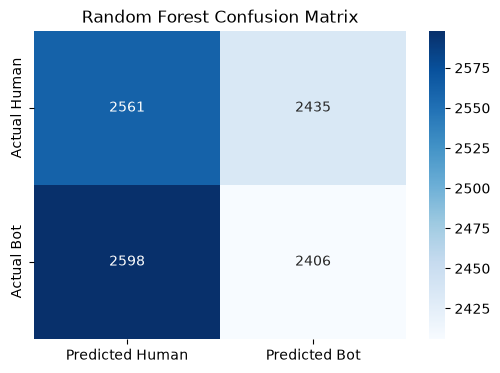

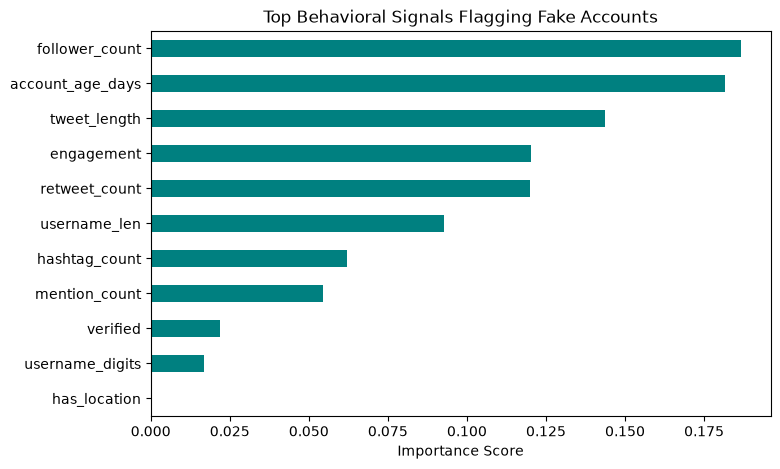

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

X, y = df[features], df["bot_label"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler().fit(X_tr)

lr = LogisticRegression(max_iter=1000).fit(scaler.transform(X_tr), y_tr)
rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1).fit(X_tr, y_tr)

print("--- LOGISTIC REGRESSION REPORT ---")
print(classification_report(y_te, lr.predict(scaler.transform(X_te))))

print("--- RANDOM FOREST REPORT ---")
print(classification_report(y_te, rf.predict(X_te)))

# Save Chart 4: Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_te, rf.predict(X_te)), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicted Human", "Predicted Bot"],
            yticklabels=["Actual Human", "Actual Bot"])
plt.title("Random Forest Confusion Matrix")
plt.savefig("../images/04_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

# Save Chart 5: Feature Importance
plt.figure(figsize=(8, 5))
imp = pd.Series(rf.feature_importances_, index=features).sort_values()
imp.plot(kind="barh", color="teal", title="Top Behavioral Signals Flagging Fake Accounts")
plt.xlabel("Importance Score")
plt.savefig("../images/05_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()


In [14]:
from sklearn.neighbors import NearestNeighbors

# 1. Euclidean Distance Clone Detection
X_all = StandardScaler().fit_transform(df[features])
nn = NearestNeighbors(n_neighbors=2, metric="euclidean", n_jobs=-1).fit(X_all)
dist, idx = nn.kneighbors(X_all)  # column 0 = itself, column 1 = closest neighbor

df["nearest_dist"] = dist[:, 1]
df["nearest_user"] = df["username"].values[idx[:, 1]]

# Flag closest 2% of accounts as suspected behavioral clones
threshold = df["nearest_dist"].quantile(0.02)
clones = df[df["nearest_dist"] <= threshold][["user_id", "username", "nearest_user", "nearest_dist", "bot_label"]]
clones.to_csv("../outputs/clone_pairs.csv", index=False)
print(f"Suspected clone-like accounts flagged (<= {threshold:.4f} distance): {len(clones)}")

# 2. Decision Support: Operational Risk Tiers
df["fake_probability"] = rf.predict_proba(df[features])[:, 1]
df["risk_tier"] = pd.cut(
    df["fake_probability"],
    bins=[-0.01, 0.5, 0.8, 1.0],
    labels=["Low - no action", "Medium - manual review", "High - priority review"]
)

print("\n--- OPERATIONAL RISK TIER DISTRIBUTION (%) ---")
print(df["risk_tier"].value_counts(normalize=True).mul(100).round(1))

df[["user_id", "username", "bot_label", "fake_probability", "risk_tier", "nearest_user", "nearest_dist"]] \
    .to_csv("../outputs/predictions.csv", index=False)
print("\nAll output files saved successfully in outputs/!")


Suspected clone-like accounts flagged (<= 0.3858 distance): 1001

--- OPERATIONAL RISK TIER DISTRIBUTION (%) ---
risk_tier
Low - no action           50.3
High - priority review    26.0
Medium - manual review    23.7
Name: proportion, dtype: float64

All output files saved successfully in outputs/!


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Standardize column names (lowercase with underscores)
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")

# 2. Check missing values before cleaning
print("--- MISSING VALUES BEFORE CLEANING ---")
print(df.isna().sum())

# 3. Clean duplicates, dates, and missing text fields
df = df.drop_duplicates()
df["created_at"] = pd.to_datetime(df["created_at"], errors="coerce")
df["location"] = df["location"].fillna("Unknown")
df["hashtags"] = df["hashtags"].fillna("")
df["verified"] = df["verified"].astype(int)

# 4. Feature Engineering (Creating Business Analyst Behavioral Signals)
df["tweet_length"] = df["tweet"].astype(str).str.len()
df["hashtag_count"] = df["hashtags"].astype(str).apply(lambda x: len([h for h in x.split() if h]))
df["has_location"] = (df["location"] != "Unknown").astype(int)
df["account_age_days"] = (pd.Timestamp.today() - df["created_at"]).dt.days
df["engagement"] = df["retweet_count"] + df["mention_count"]
df["username_len"] = df["username"].astype(str).str.len()
df["username_digits"] = df["username"].astype(str).str.count(r"\d")

# 5. Drop any rows where engineered features or target label became null
features = [
    "retweet_count", "mention_count", "follower_count", "verified",
    "tweet_length", "hashtag_count", "has_location",
    "account_age_days", "engagement", "username_len", "username_digits"
]
df = df.dropna(subset=features + ["bot_label"])

# 6. Save cleaned dataset to data/processed/
df.to_csv("../data/processed/cleaned_data.csv", index=False)
print("\nCleaned dataset saved! Final shape:", df.shape)


--- MISSING VALUES BEFORE CLEANING ---
user_id              0
username             0
tweet                0
retweet_count        0
mention_count        0
follower_count       0
verified             0
bot_label            0
location             0
created_at           0
hashtags          8341
dtype: int64

Cleaned dataset saved! Final shape: (50000, 18)


C:\Users\Dasari Pallavi\AppData\Local\Temp\ipykernel_16908\1111283096.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="bot_label", data=df, palette="Set2")


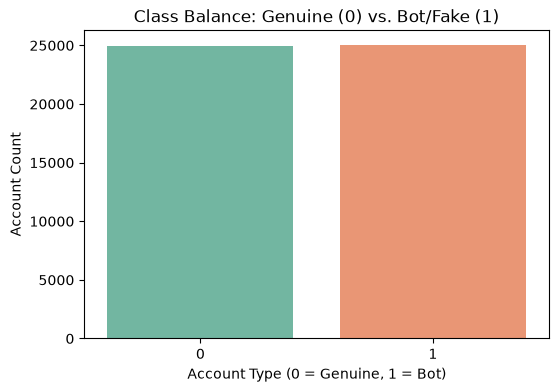

C:\Users\Dasari Pallavi\AppData\Local\Temp\ipykernel_16908\1111283096.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="bot_label", y=col, data=df, palette="Set3")


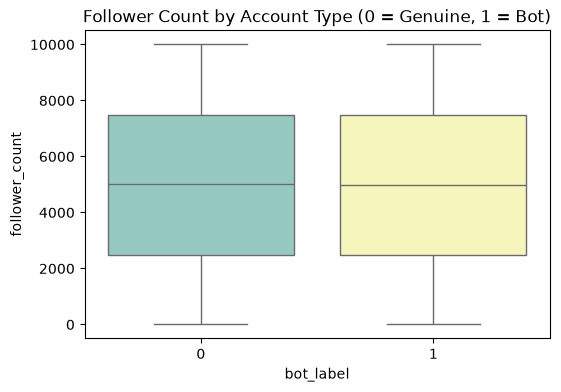

C:\Users\Dasari Pallavi\AppData\Local\Temp\ipykernel_16908\1111283096.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="bot_label", y=col, data=df, palette="Set3")


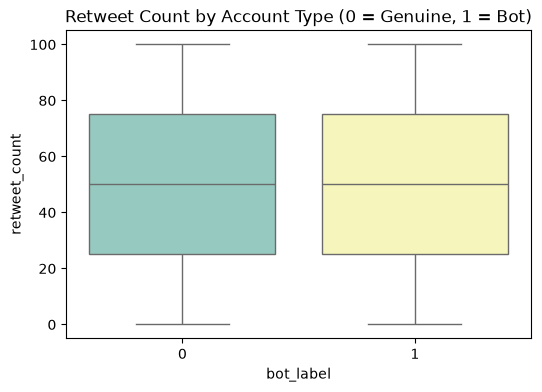

C:\Users\Dasari Pallavi\AppData\Local\Temp\ipykernel_16908\1111283096.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="bot_label", y=col, data=df, palette="Set3")


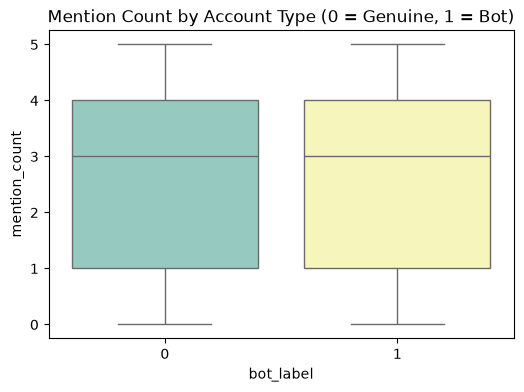

C:\Users\Dasari Pallavi\AppData\Local\Temp\ipykernel_16908\1111283096.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="bot_label", y=col, data=df, palette="Set3")


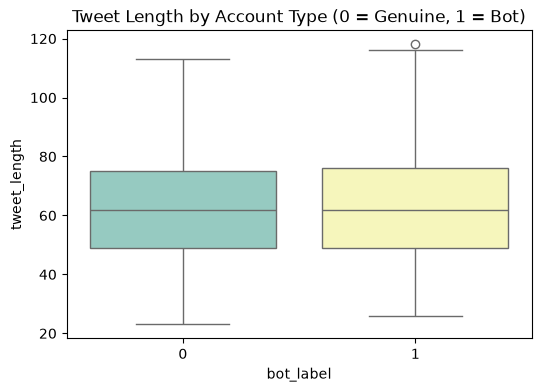

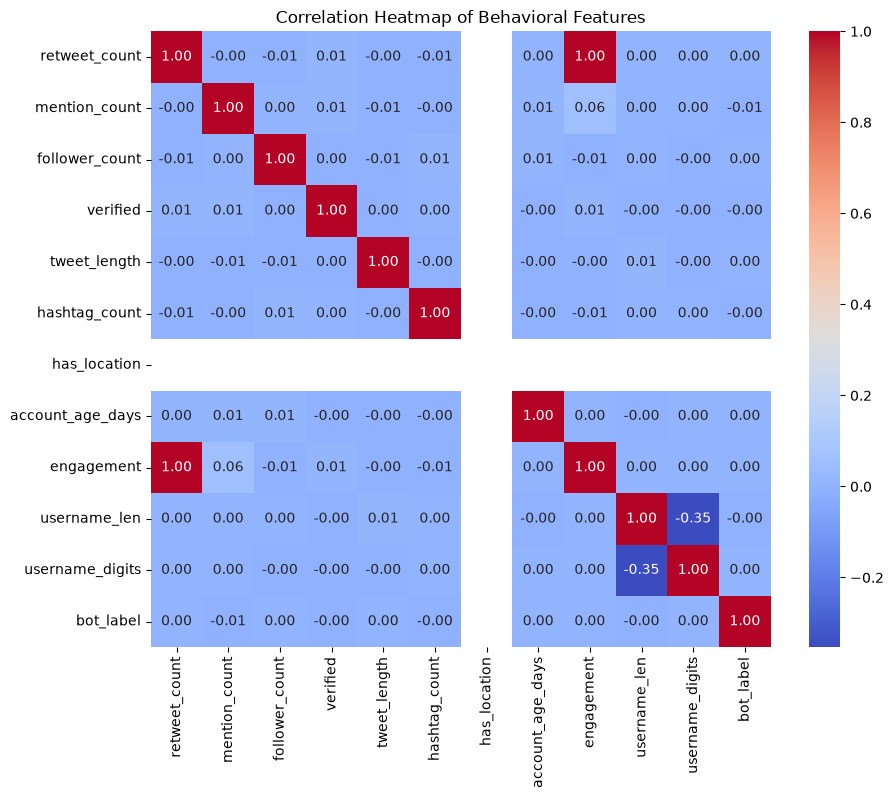

In [4]:
# Chart 1: Bot vs Human Account Balance
plt.figure(figsize=(6, 4))
sns.countplot(x="bot_label", data=df, palette="Set2")
plt.title("Class Balance: Genuine (0) vs. Bot/Fake (1)")
plt.xlabel("Account Type (0 = Genuine, 1 = Bot)")
plt.ylabel("Account Count")
plt.savefig("../images/01_class_balance.png", dpi=150, bbox_inches="tight")
plt.show()

# Charts 2a–2d: Behavioral Distributions across Key Metrics
for idx, col in enumerate(["follower_count", "retweet_count", "mention_count", "tweet_length"], start=1):
    plt.figure(figsize=(6, 4))
    sns.boxplot(x="bot_label", y=col, data=df, palette="Set3")
    plt.title(f"{col.replace('_', ' ').title()} by Account Type (0 = Genuine, 1 = Bot)")
    plt.savefig(f"../images/02{chr(96+idx)}_{col}_box.png", dpi=150, bbox_inches="tight")
    plt.show()

# Chart 3: Feature Correlation Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df[features + ["bot_label"]].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap of Behavioral Features")
plt.savefig("../images/03_correlation.png", dpi=150, bbox_inches="tight")
plt.show()


In [6]:
kpi = {
    "Total accounts": len(df),
    "Fake/bot rate (%)": round(df["bot_label"].mean() * 100, 2),
    "Verified among bots (%)": round(df[df.bot_label == 1]["verified"].mean() * 100, 2),
    "Verified among humans (%)": round(df[df.bot_label == 0]["verified"].mean() * 100, 2),
    "Avg followers - bots": round(df[df.bot_label == 1]["follower_count"].mean(), 1),
    "Avg followers - humans": round(df[df.bot_label == 0]["follower_count"].mean(), 1),
    "Avg engagement - bots": round(df[df.bot_label == 1]["engagement"].mean(), 1),
    "Avg engagement - humans": round(df[df.bot_label == 0]["engagement"].mean(), 1),
}

kpi_series = pd.Series(kpi)
kpi_series.to_csv("../outputs/kpis.csv", header=["Value"])
print("--- BUSINESS KPI SUMMARY ---")
print(kpi_series)


--- BUSINESS KPI SUMMARY ---
Total accounts               50000.00
Fake/bot rate (%)               50.04
Verified among bots (%)         49.88
Verified among humans (%)       50.14
Avg followers - bots          4991.90
Avg followers - humans        4985.30
Avg engagement - bots           52.50
Avg engagement - humans         52.50
dtype: float64


--- LOGISTIC REGRESSION REPORT ---
              precision    recall  f1-score   support

           0       0.49      0.48      0.49      4996
           1       0.49      0.51      0.50      5004

    accuracy                           0.49     10000
   macro avg       0.49      0.49      0.49     10000
weighted avg       0.49      0.49      0.49     10000

--- RANDOM FOREST REPORT ---
              precision    recall  f1-score   support

           0       0.50      0.51      0.51      4996
           1       0.50      0.49      0.50      5004

    accuracy                           0.50     10000
   macro avg       0.50      0.50      0.50     10000
weighted avg       0.50      0.50      0.50     10000



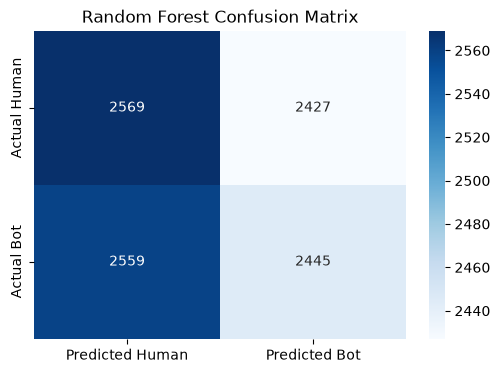

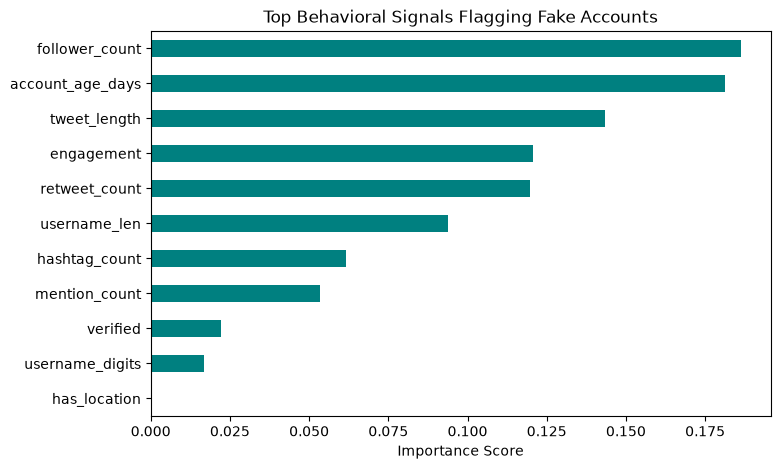

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

X, y = df[features], df["bot_label"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler().fit(X_tr)

lr = LogisticRegression(max_iter=1000).fit(scaler.transform(X_tr), y_tr)
rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1).fit(X_tr, y_tr)

print("--- LOGISTIC REGRESSION REPORT ---")
print(classification_report(y_te, lr.predict(scaler.transform(X_te))))

print("--- RANDOM FOREST REPORT ---")
print(classification_report(y_te, rf.predict(X_te)))

# Save Chart 4: Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_te, rf.predict(X_te)), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicted Human", "Predicted Bot"],
            yticklabels=["Actual Human", "Actual Bot"])
plt.title("Random Forest Confusion Matrix")
plt.savefig("../images/04_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

# Save Chart 5: Feature Importance
plt.figure(figsize=(8, 5))
imp = pd.Series(rf.feature_importances_, index=features).sort_values()
imp.plot(kind="barh", color="teal", title="Top Behavioral Signals Flagging Fake Accounts")
plt.xlabel("Importance Score")
plt.savefig("../images/05_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()


In [8]:
from sklearn.neighbors import NearestNeighbors

# 1. Euclidean Distance Clone Detection
X_all = StandardScaler().fit_transform(df[features])
nn = NearestNeighbors(n_neighbors=2, metric="euclidean", n_jobs=-1).fit(X_all)
dist, idx = nn.kneighbors(X_all)  # column 0 = itself, column 1 = closest neighbor

df["nearest_dist"] = dist[:, 1]
df["nearest_user"] = df["username"].values[idx[:, 1]]

# Flag closest 2% of accounts as suspected behavioral clones
threshold = df["nearest_dist"].quantile(0.02)
clones = df[df["nearest_dist"] <= threshold][["user_id", "username", "nearest_user", "nearest_dist", "bot_label"]]
clones.to_csv("../outputs/clone_pairs.csv", index=False)
print(f"Suspected clone-like accounts flagged (<= {threshold:.4f} distance): {len(clones)}")

# 2. Decision Support: Operational Risk Tiers
df["fake_probability"] = rf.predict_proba(df[features])[:, 1]
df["risk_tier"] = pd.cut(
    df["fake_probability"],
    bins=[-0.01, 0.5, 0.8, 1.0],
    labels=["Low - no action", "Medium - manual review", "High - priority review"]
)

print("\n--- OPERATIONAL RISK TIER DISTRIBUTION (%) ---")
print(df["risk_tier"].value_counts(normalize=True).mul(100).round(1))

df[["user_id", "username", "bot_label", "fake_probability", "risk_tier", "nearest_user", "nearest_dist"]] \
    .to_csv("../outputs/predictions.csv", index=False)
print("\nAll output files saved successfully in outputs/!")


Suspected clone-like accounts flagged (<= 0.3858 distance): 1001

--- OPERATIONAL RISK TIER DISTRIBUTION (%) ---
risk_tier
Low - no action           50.2
High - priority review    26.2
Medium - manual review    23.6
Name: proportion, dtype: float64

All output files saved successfully in outputs/!
